<a href="https://colab.research.google.com/github/AmitKunduA/Class_Assignment/blob/main/Clustering_Techniques.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Mall Customer Dataset.

In [ ]:
# Install necessary libraries
!pip install -q -U matplotlib seaborn pandas scikit-learn

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [ ]:
# Load the Mall Customer Segmentation dataset
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/python/Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


# Data Preprocessing and Exploration

In [ ]:
# Explore the dataset - check for missing values and basic info
df.info()

# Selecting relevant columns for clustering (Annual Income and Spending Score)
df = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Check for null values
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Annual Income (k$)      200 non-null    int64
 1   Spending Score (1-100)  200 non-null    int64
dtypes: int64(2)
memory usage: 3.3 KB


Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

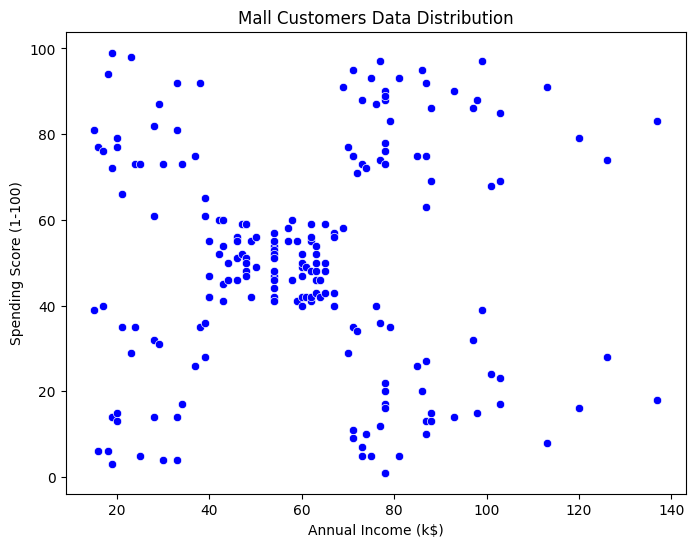

In [ ]:
# Standardize the data (important for K-Means)
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)

# Visualize the data distribution
plt.figure(figsize=(8, 6))
sns.scatterplot(x=df['Annual Income (k$)'], y=df['Spending Score (1-100)'], color='blue')
plt.title('Mall Customers Data Distribution')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

# K-means clustering

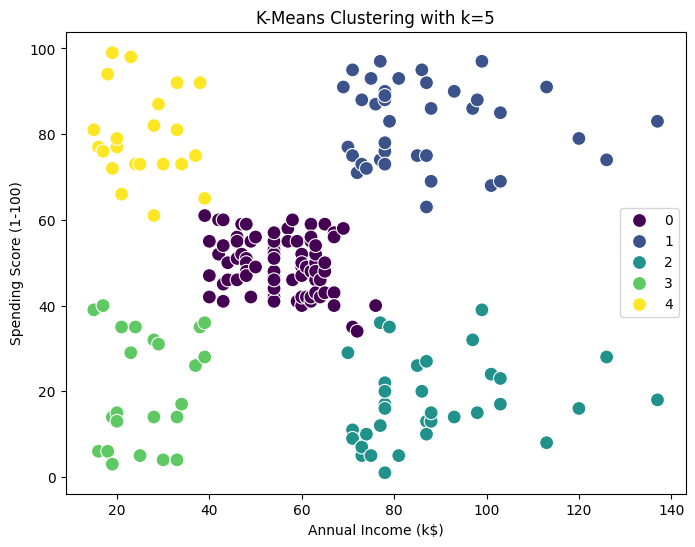

In [ ]:
# --- K-Means Clustering ---
from sklearn.cluster import KMeans
optimal_k = 5
kmeans =KMeans(n_clusters=optimal_k, random_state=20)
kmeans.fit(df_scaled)

# Visualize the K-Means clusters
plt.figure(figsize=(8, 6))
sns.scatterplot(x=df['Annual Income (k$)'], y=df['Spending Score (1-100)'], hue=kmeans.labels_, palette='viridis', s=100)
plt.title(f'K-Means Clustering with k={optimal_k}')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

# Hierarchical Clustering

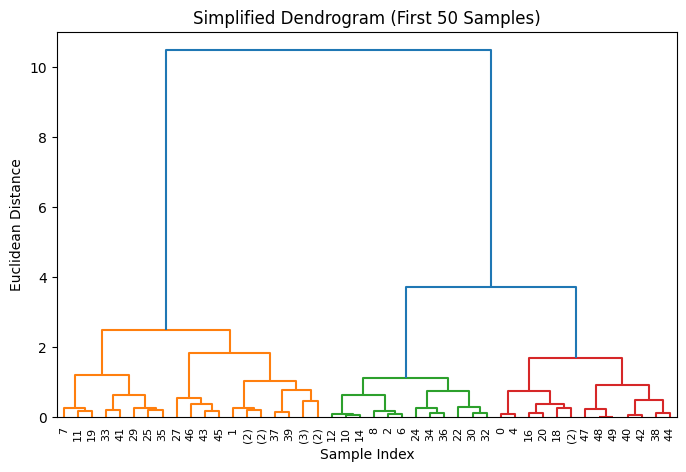

In [ ]:
# --- Hierarchical Clustering (Simplified Dendrogram) ---
# Use a subset of the data to keep visualization readable
from scipy.cluster.hierarchy import dendrogram, linkage
sample_data = df_scaled[:50]  # taking first 50 samples

# Create linkage matrix
linked = linkage(sample_data, method='ward')

# Plot the simplified dendrogram
plt.figure(figsize=(8, 5))
dendrogram(
    linked,
    truncate_mode='level',  # show only top levels of the tree
    p=5,                    # show last 5 merges
    color_threshold=3
)
plt.title('Simplified Dendrogram (First 50 Samples)')
plt.xlabel('Sample Index')
plt.ylabel('Euclidean Distance')
plt.show()


# Comparison between K-means and Hierarchical

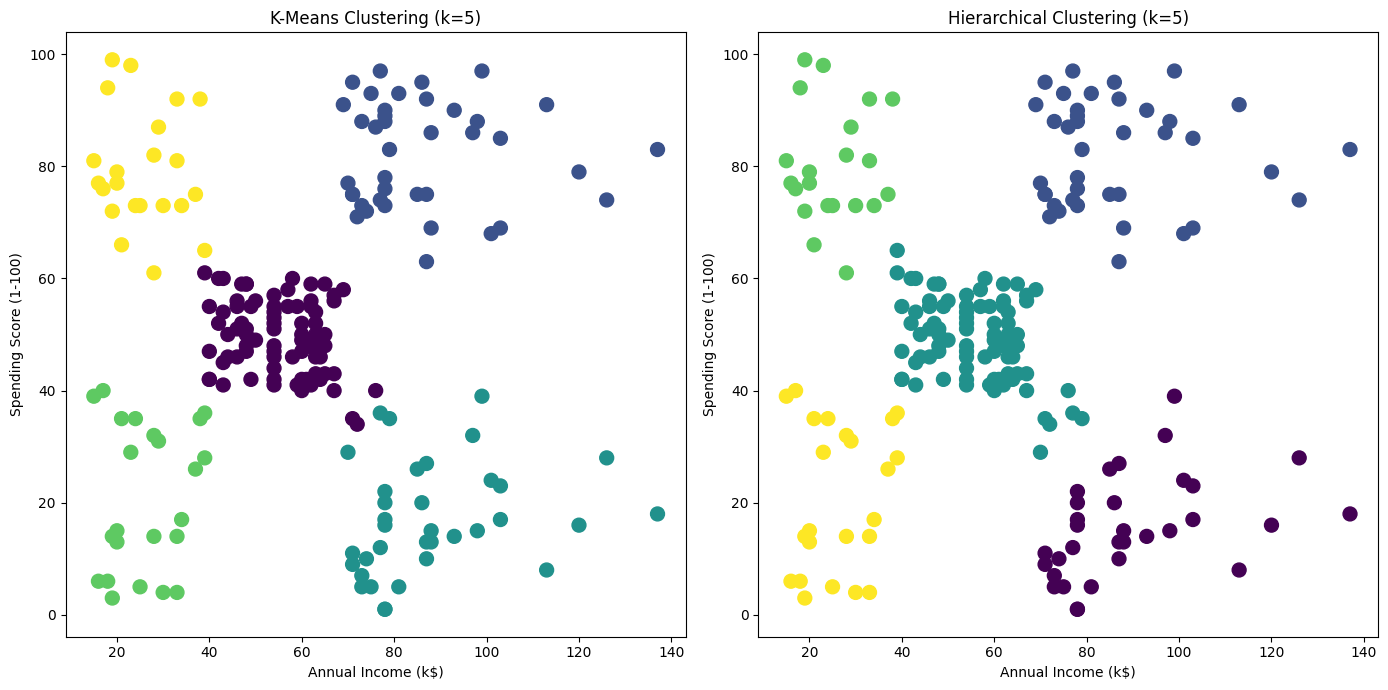

In [ ]:
# Apply Agglomerative Clustering (Hierarchical) with k=5
from sklearn.cluster import AgglomerativeClustering
hierarchical = AgglomerativeClustering(n_clusters=5, linkage='ward')
y_hc = hierarchical.fit_predict(df_scaled)

# Plot the comparison of K-Means and Hierarchical Clustering
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))

# K-Means plot
ax1.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], c=kmeans.labels_, cmap='viridis', s=100)
ax1.set_title(f'K-Means Clustering (k={optimal_k})')
ax1.set_xlabel('Annual Income (k$)')
ax1.set_ylabel('Spending Score (1-100)')

# Hierarchical plot
ax2.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], c=y_hc, cmap='viridis', s=100)
ax2.set_title('Hierarchical Clustering (k=5)')
ax2.set_xlabel('Annual Income (k$)')
ax2.set_ylabel('Spending Score (1-100)')

plt.tight_layout()
plt.show()

#1 Socio-Economic Factors and Income Dataset.

#1 Load, Data preprocessing and Exploration

In [16]:
!pip install -q -U matplotlib seaborn pandas scikit-learn

import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
df = pd.read_csv('/content/drive/MyDrive/python/sgdata.csv')
df.head()

,ID,Sex,Marital status,Age,Education,Income,Occupation,Settlement size
0,100000001,0,single,67,university,124670,skilled employee / official,2
1,100000002,1,non-single (divorced / separated / married / w...,22,high school,150773,skilled employee / official,2
2,100000003,0,single,49,high school,89210,unemployed / unskilled,0
3,100000004,0,single,45,high school,171565,skilled employee / official,1
4,100000005,0,single,53,high school,149031,skilled employee / official,1


In [4]:
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   ID               2000 non-null   int64
 1   Sex              2000 non-null   int64
 2   Marital status   2000 non-null   str  
 3   Age              2000 non-null   int64
 4   Education        2000 non-null   str  
 5   Income           2000 non-null   int64
 6   Occupation       2000 non-null   str  
 7   Settlement size  2000 non-null   int64
dtypes: int64(5), str(3)
memory usage: 263.7 KB


ID                 0
Sex                0
Marital status     0
Age                0
Education          0
Income             0
Occupation         0
Settlement size    0
dtype: int64

In [17]:
from sklearn.preprocessing import LabelEncoder
for col in df.select_dtypes(include='object').columns:
    df[col] = LabelEncoder().fit_transform(df[col])

df.head()

,ID,Sex,Marital status,Age,Education,Income,Occupation,Settlement size
0,100000001,0,1,67,3,124670,1,2
1,100000002,1,0,22,1,150773,1,2
2,100000003,0,1,49,1,89210,2,0
3,100000004,0,1,45,1,171565,1,1
4,100000005,0,1,53,1,149031,1,1


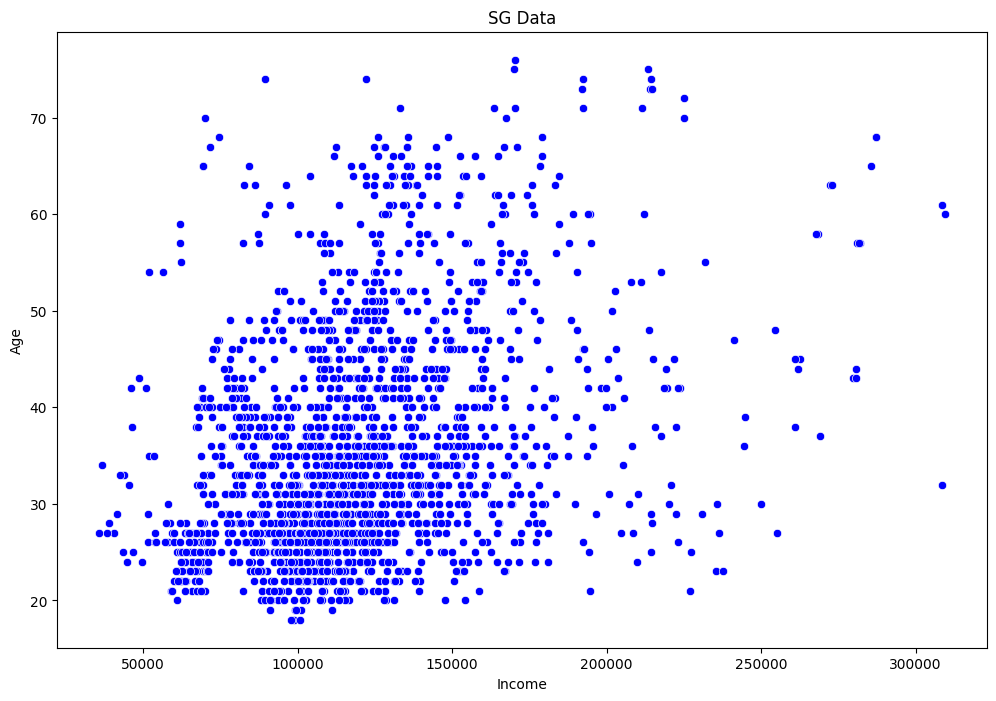

In [7]:
import matplotlib.pyplot as plt
scaler= StandardScaler()
df_scaled= scaler.fit_transform(df)

plt.figure(figsize=(12, 8))
sns.scatterplot(x=df['Income'], y=df['Age'], color='blue')
plt.title('SG Data')
plt.xlabel('Income')
plt.ylabel('Age')
plt.show()

#1 K-means clustering

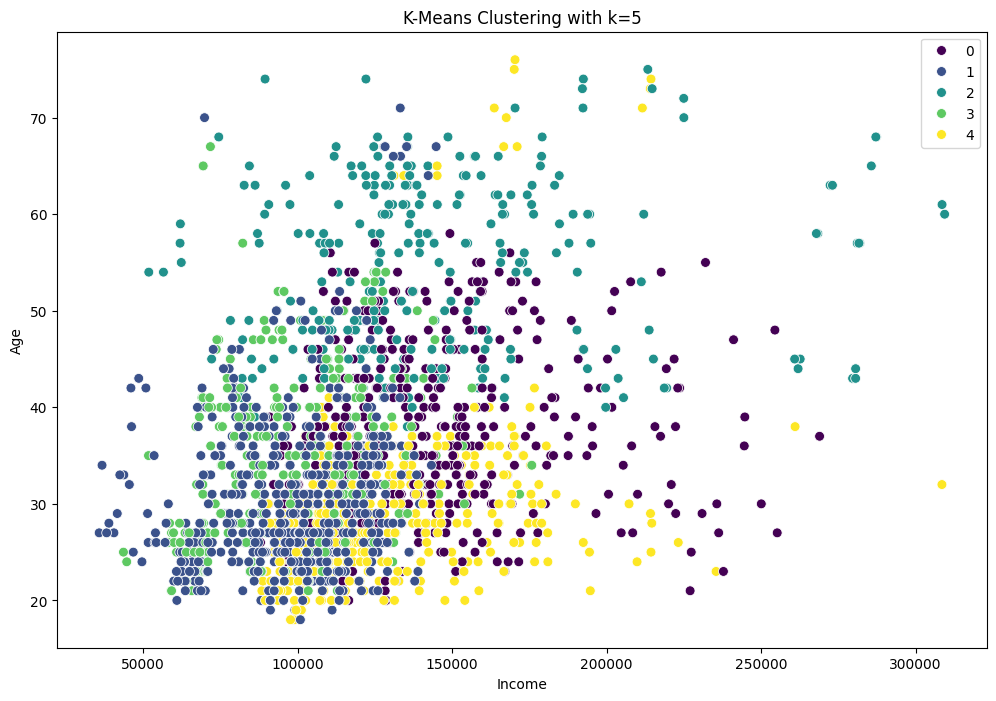

In [8]:
from sklearn.cluster import KMeans
kmeans=KMeans(n_clusters=5, random_state=20)
kmeans.fit(df_scaled)

plt.figure(figsize=(12, 8))
sns.scatterplot(x=df['Income'], y=df['Age'], hue=kmeans.labels_, palette='viridis', s=50)
plt.title('K-Means Clustering with k=5')
plt.xlabel('Income')
plt.ylabel('Age')
plt.show()

#1 Hierarchical Clustering

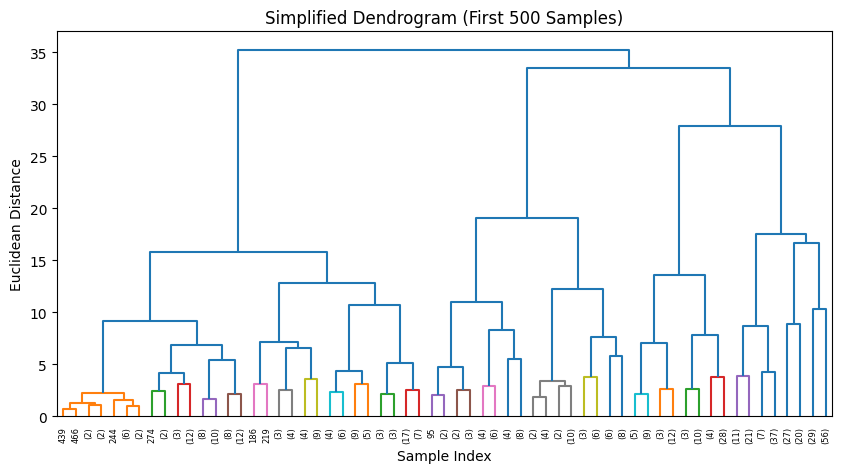

In [14]:
from scipy.cluster.hierarchy import dendrogram, linkage
sample_data=df_scaled[:500]

linked=linkage(sample_data, method='ward' )

plt.figure(figsize=(10, 5))
dendrogram(
    linked,
    truncate_mode='level',
    p=5,
    color_threshold=4,
)
plt.title('Simplified Dendrogram (First 500 Samples)')
plt.xlabel('Sample Index')
plt.ylabel('Euclidean Distance')
plt.show()

#1 Comparison Between K-Means and Hierarchical

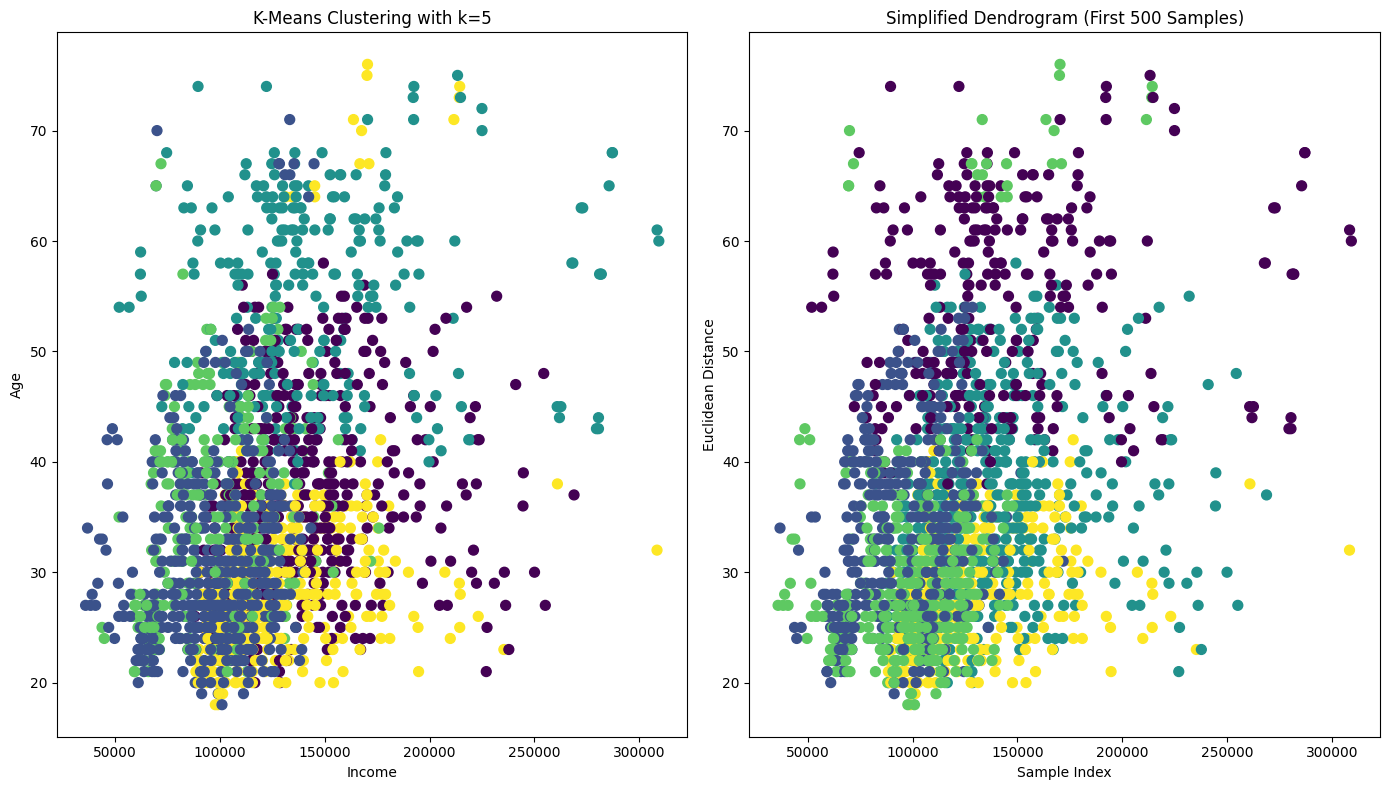

In [15]:
from sklearn.cluster import AgglomerativeClustering
hierarchical= AgglomerativeClustering(n_clusters=5, linkage='ward')
h_cl=hierarchical.fit_predict(df_scaled)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8))

ax1.scatter(x=df['Income'], y=df['Age'], c=kmeans.labels_, cmap='viridis', s=50)
ax1.set_title('K-Means Clustering with k=5')
ax1.set_xlabel('Income')
ax1.set_ylabel('Age')

ax2.scatter(x=df['Income'], y=df['Age'], c=h_cl, cmap='viridis', s=50)
ax2.set_title('Simplified Dendrogram (First 500 Samples)')
ax2.set_xlabel('Sample Index')
ax2.set_ylabel('Euclidean Distance')

plt.tight_layout()
plt.show()